##ARIMA
Autocorrelation Function (ACF): The ACF measures the correlation between a time series and its lagged values, including both direct and indirect effects. For example, the correlation at lag 3 (ACF(3)) includes the influence of lag 1 and lag 2 on lag 3. It helps identify the 'q' (moving average) parameter of an ARIMA model by showing the extent of pure moving average components.

Partial Autocorrelation Function (PACF): The PACF measures the correlation between a time series and its lagged values after removing the linear dependence of the intermediate lags. For example, PACF(3) measures the correlation between the current value and the value three periods ago, after controlling for the values one and two periods ago. It helps identify the 'p' (autoregressive) parameter of an ARIMA model by showing the extent of pure autoregressive components.

Mounted at /content/gdrive
The value of d is: 0


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:           Weekly_Sales   No. Observations:                  107
Model:                 ARIMA(2, 2, 2)   Log Likelihood               -1491.829
Date:                Tue, 12 May 2026   AIC                           2993.658
Time:                        00:43:34   BIC                           3006.928
Sample:                    02-05-2010   HQIC                          2999.035
                         - 02-17-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9278      0.421     -2.206      0.027      -1.752      -0.103
ar.L2         -0.0497      0.129     -0.385      0.700      -0.303       0.203
ma.L1         -0.1809      0.429     -0.422      0.6

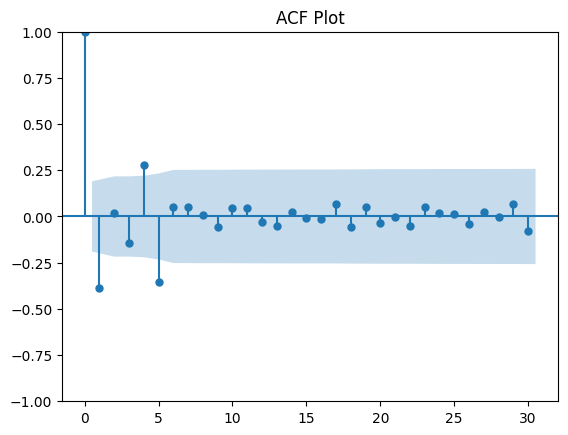

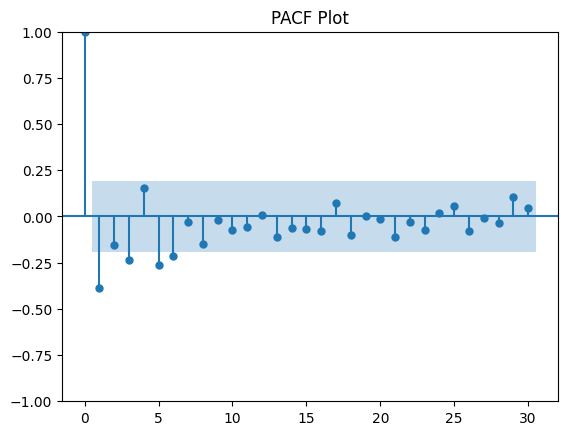

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/gdrive/MyDrive/Tina AI study/Walmart_Sales.csv', encoding='latin1')

df['Date'] = pd.to_datetime(
    df['Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

sales_mean = df.groupby('Store')['Weekly_Sales'].mean().reset_index()
#print(sales_mean)
sales_mean = sales_mean.sort_values(
    'Weekly_Sales',
    ascending=False
)
#print(sales_mean.head())
best_store = sales_mean.iloc[0]['Store']
#print(best_store)


best_store_df = df[df['Store'] == best_store].copy()

sales_by_date = best_store_df[['Date', 'Weekly_Sales']].copy()
sales_by_date = sales_by_date .sort_values('Date')

#print(sales_by_date.head())
#print(sales_by_date.tail())

arima = sales_by_date.set_index('Date')['Weekly_Sales']

split_ind = int(len(arima) * 0.75)

train = arima.iloc[:split_ind]
test = arima.iloc[split_ind:]

from statsmodels.tsa.arima.model import ARIMA

d = 1
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train)


if adf_result[1] <= 0.05:
    d = 0
else:
    d = 1
print(f"The value of d is: {d}")
arima_model = ARIMA(train, order=(2, 2, 2))

arima_result = arima_model.fit() # trained model
print(arima_result.summary())

forecast = arima_result.forecast(steps=len(test)) #forecasting
print("Forecast\n",forecast)

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plot_acf(train.diff().dropna(), lags=30)
plt.title("ACF Plot")
plt.show()

plot_pacf(train.diff().dropna(), lags=30)
plt.title("PACF Plot")
plt.show()

To difference the data, you can use the `.diff()` method on your time series. This calculates the difference between an element and a previous element (specified by `periods`). A first-order differencing (i.e., `periods=1`) is commonly used to remove trends and achieve stationarity.

Original data head:
 Date
2010-02-05    2401395.47
2010-02-12    2109107.90
2010-02-19    2161549.76
2010-02-26    1898193.95
2010-03-05    2119213.72
Name: Weekly_Sales, dtype: float64

Differenced data head:
 Date
2010-02-12   -292287.57
2010-02-19     52441.86
2010-02-26   -263355.81
2010-03-05    221019.77
2010-03-12   -108238.88
Name: Weekly_Sales, dtype: float64


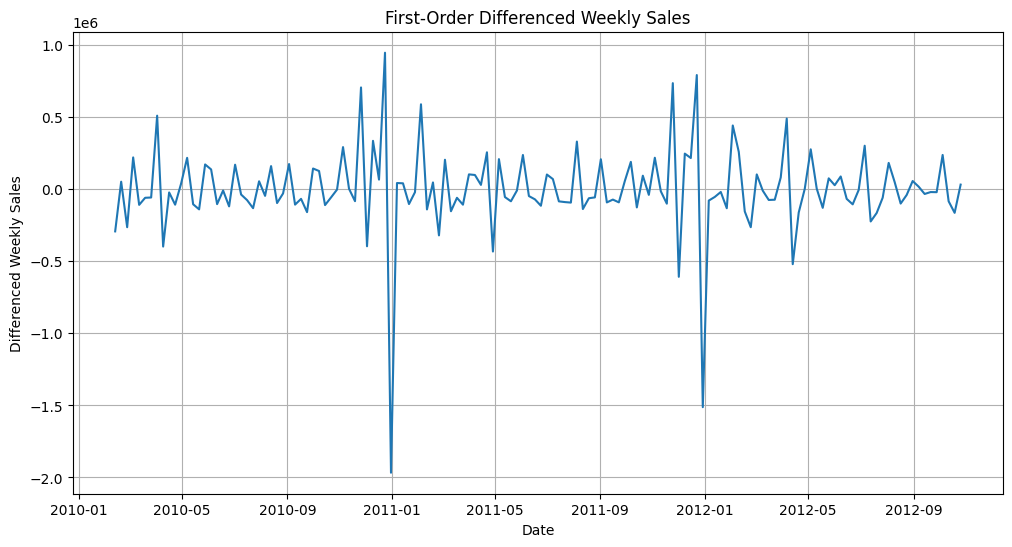

In [ ]:
# Assuming 'arima' is your time series (e.g., from cell TAISJHU6X9fG)
# Perform first-order differencing
differenced_data = arima.diff().dropna()

print("Original data head:\n", arima.head())
print("\nDifferenced data head:\n", differenced_data.head())

# You can also plot the differenced data to visually inspect for stationarity
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(differenced_data)
plt.title('First-Order Differenced Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Differenced Weekly Sales')
plt.grid(True)
plt.show()

If a first-order differencing does not achieve stationarity, you can apply second-order differencing. This means differencing the already differenced series.

Original data head:
 Date
2010-02-05    2401395.47
2010-02-12    2109107.90
2010-02-19    2161549.76
2010-02-26    1898193.95
2010-03-05    2119213.72
Name: Weekly_Sales, dtype: float64

First-order differenced data head:
 Date
2010-02-12   -292287.57
2010-02-19     52441.86
2010-02-26   -263355.81
2010-03-05    221019.77
2010-03-12   -108238.88
Name: Weekly_Sales, dtype: float64

Second-order differenced data head:
 Date
2010-03-26   -10303601.50
2010-04-02     7079039.87
2010-04-09    -6348624.21
2010-04-16    11149032.64
2010-04-23   -16761944.57
Name: Weekly_Sales, dtype: float64


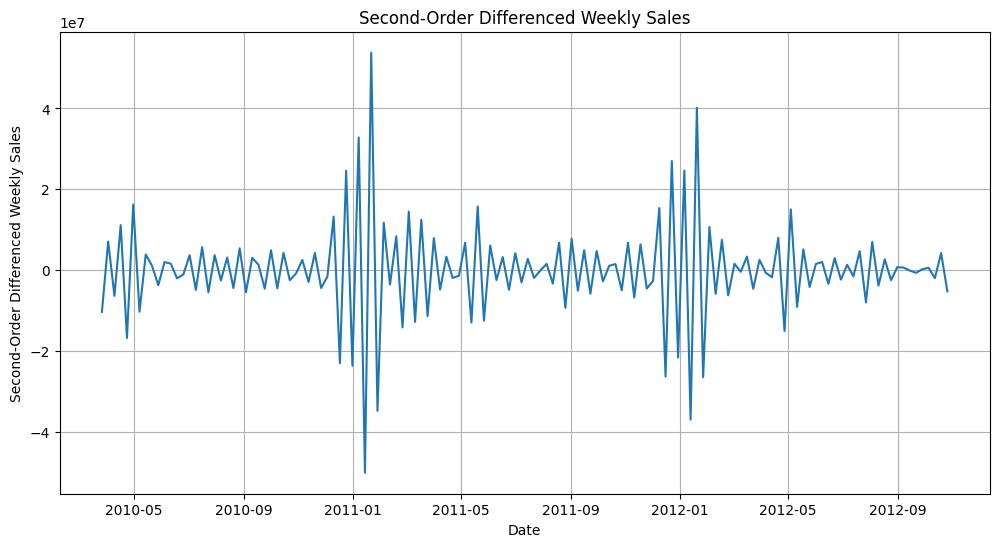

In [ ]:
# Perform second-order differencing
# This means applying .diff() twice
second_order_differenced_data = arima.diff().diff().diff().diff().diff().diff().diff().dropna()

print("Original data head:\n", arima.head())
print("\nFirst-order differenced data head:\n", differenced_data.head())
print("\nSecond-order differenced data head:\n", second_order_differenced_data.head())

# Plot the second-order differenced data
plt.figure(figsize=(12, 6))
plt.plot(second_order_differenced_data)
plt.title('Second-Order Differenced Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Second-Order Differenced Weekly Sales')
plt.grid(True)
plt.show()

            Weekly_Sales
Date                    
2012-02-24    2045837.55
2012-03-02    2148822.76
2012-03-09    2139265.40
2012-03-16    2064991.71
2012-03-23    1992436.96
2012-03-30    2074721.74
2012-04-06    2565259.92
2012-04-13    2045396.06
2012-04-20    1884427.84
2012-04-27    1886503.93
2012-05-04    2163510.89
2012-05-11    2168097.11
2012-05-18    2039222.26
2012-05-25    2114989.00
2012-06-01    2143126.59
2012-06-08    2231962.13
2012-06-15    2165160.29
2012-06-22    2060588.69
2012-06-29    2055952.61
2012-07-06    2358055.30
2012-07-13    2134680.12
2012-07-20    1970170.29
2012-07-27    1911559.10
2012-08-03    2094515.71
2012-08-10    2144245.39
2012-08-17    2045061.22
2012-08-24    2005341.43
2012-08-31    2062481.56
2012-09-07    2080529.06
2012-09-14    2047949.98
2012-09-21    2028587.24
2012-09-28    2008350.58
2012-10-05    2246411.89
2012-10-12    2162951.36
2012-10-19    1999363.49
2012-10-26    2031650.55
            Weekly_Sales     Predicted
Date       

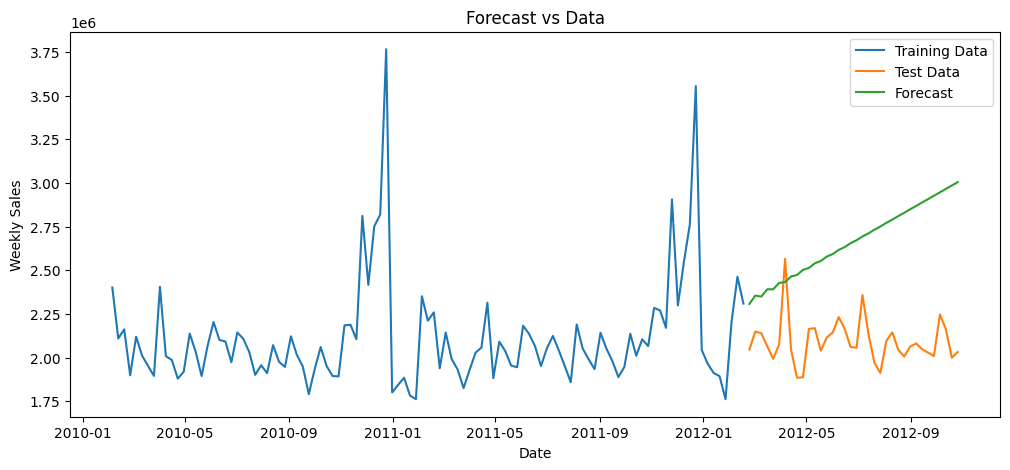

In [ ]:
results = test.to_frame()
print(results)
results.columnd = 'Actual'
results['Predicted'] = forecast.values

print(results.head())

plt.figure(figsize=(12,5))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Test Data')
plt.plot(results.index, results['Predicted'], label='Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title('Forecast vs Data')
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
eval_df = test.to_frame()
eval_df.columns = ['actual']
eval_df['prediction'] = forecast.values
eval_df['forecast_error'] = eval_df['actual'] - eval_df['prediction']

eval_df['absolute_percentage_error'] = (
    eval_df['forecast_error'].abs() / eval_df['actual']
) * 100

arima_mape = eval_df['absolute_percentage_error'].mean()

print("MAPE:", arima_mape)

MAPE: 28.05627969855764


##random Forest

Mounted at /content/gdrive
p-value: 0.000117
20.0
Corr Matrix:-  Weekly_Sales    1.000000
lag_1           0.381550
month           0.355361
week            0.337603
lag_2           0.223447
lag_4           0.154124
Holiday_Flag    0.140983
lag_3           0.090290
Date            0.071747
CPI             0.058706
Fuel_Price     -0.013507
year           -0.043628
Unemployment   -0.095341
Temperature    -0.264983
Name: Weekly_Sales, dtype: float64
MAPE: 3.816487050621435


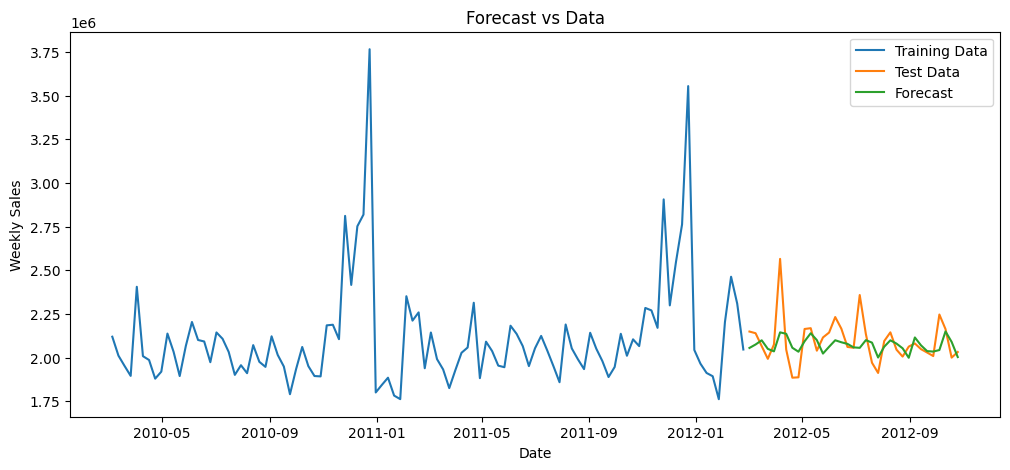

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv('/content/gdrive/MyDrive/Tina AI study/Walmart_Sales.csv', encoding='latin1')
# make it date, not test format; format is mixed, needs custom
df['Date'] = pd.to_datetime(
    df['Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)
df.head()
from statsmodels.tsa.stattools import adfuller
from numpy import log
result = adfuller(df['Weekly_Sales'].dropna())
print('p-value: %f' % result[1]) #check if data is stationary


store_sales = df.groupby('Store')['Weekly_Sales'].mean().reset_index()
store_sales = store_sales.sort_values(
    'Weekly_Sales',
    ascending=False
)

best_store = store_sales.iloc[0]['Store']
print(best_store)
# print(store_sales.head())

best_store_df = df[df['Store'] == best_store].copy()

best_store_df = best_store_df.sort_values('Date')

# print(best_store_df.head())

rf_df = best_store_df[['Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
                       'Fuel_Price', 'CPI', 'Unemployment']].copy()

rf_df = rf_df.sort_values('Date')

# print(rf_df)

# print(rf_df.dtypes)
# Seasonal variable
rf_df['year'] = rf_df['Date'].dt.year
rf_df['month'] = rf_df['Date'].dt.month
rf_df['week'] = rf_df['Date'].dt.isocalendar().week.astype(int)

# weekly sales
rf_df['lag_1'] = rf_df['Weekly_Sales'].shift(1) # last wee
rf_df['lag_2'] = rf_df['Weekly_Sales'].shift(2) # 2 weeks ago
rf_df['lag_3'] = rf_df['Weekly_Sales'].shift(3) # 3 weeks ago - ADDED THIS LINE
rf_df['lag_4'] = rf_df['Weekly_Sales'].shift(4) # a month ago

##correlation on the features
corr_matrix = rf_df.corr()
print("Corr Matrix:- ",corr_matrix['Weekly_Sales'].sort_values(ascending=False))

rf_df = rf_df.dropna() #removing missing values, getting new rf_df

# print(rf_df.head())

split_ind = int(len(rf_df) * 0.75)

train_rf = rf_df.iloc[:split_ind]
test_rf = rf_df.iloc[split_ind:]

features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_3', 'lag_4']

x_train = train_rf[features]
y_train = train_rf['Weekly_Sales']

x_test = test_rf[features]
y_test = test_rf['Weekly_Sales']

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)

y_pred = rf_model.predict(x_test)

# Estimate MAPE
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
print("MAPE:", mape)


# plot RF
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.plot(train_rf['Date'], train_rf['Weekly_Sales'], label='Training Data')
plt.plot(test_rf['Date'], test_rf['Weekly_Sales'], label='Test Data')
plt.plot(test_rf['Date'], y_pred, label='Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title('Forecast vs Data')
plt.legend()
plt.show()

### Random forest 10 best stores

Mounted at /content/gdrive
2012-03-02 00:00:00
[ 1  2  4  6 10 13 14 20 27 39]


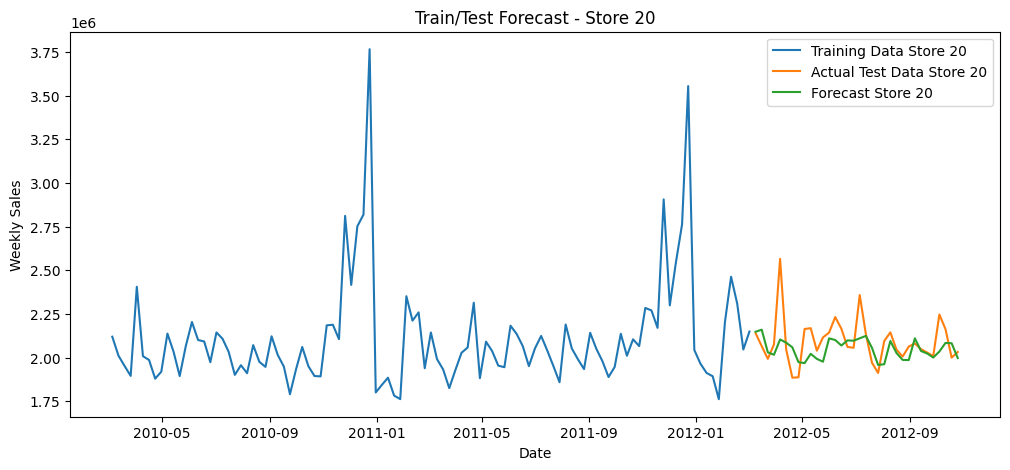

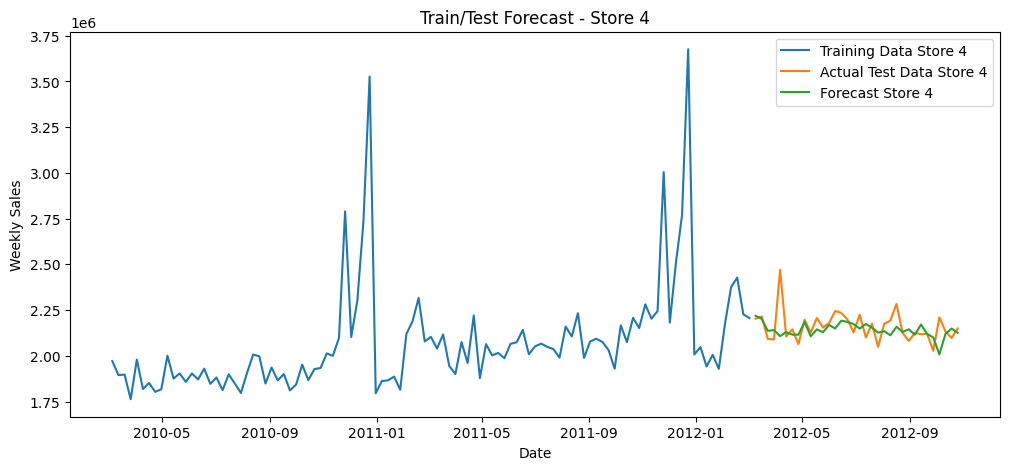

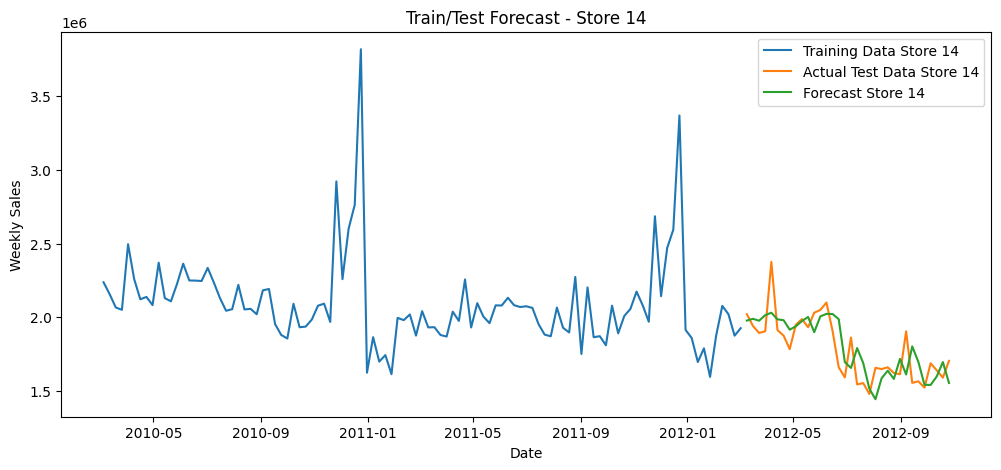

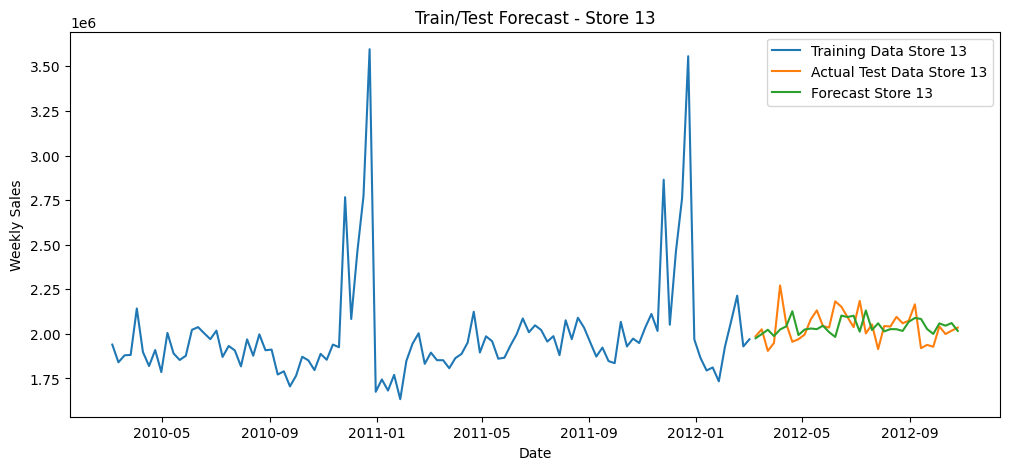

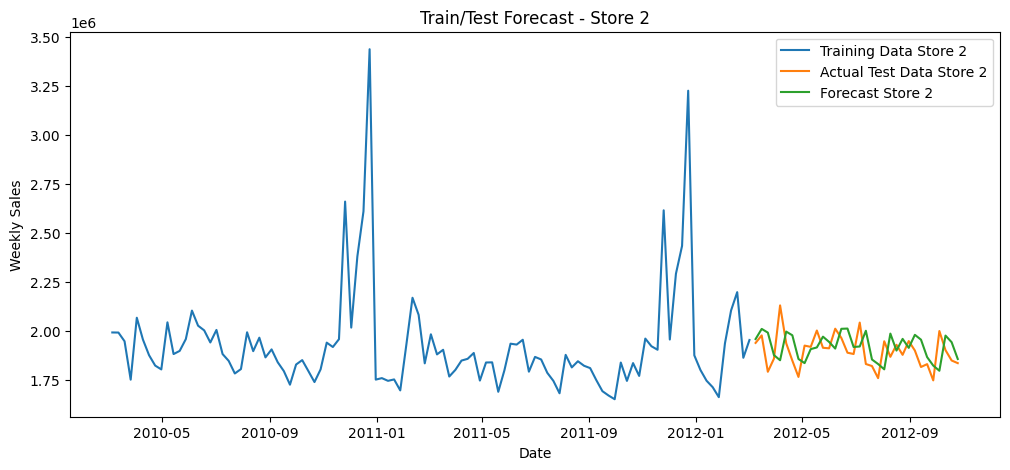

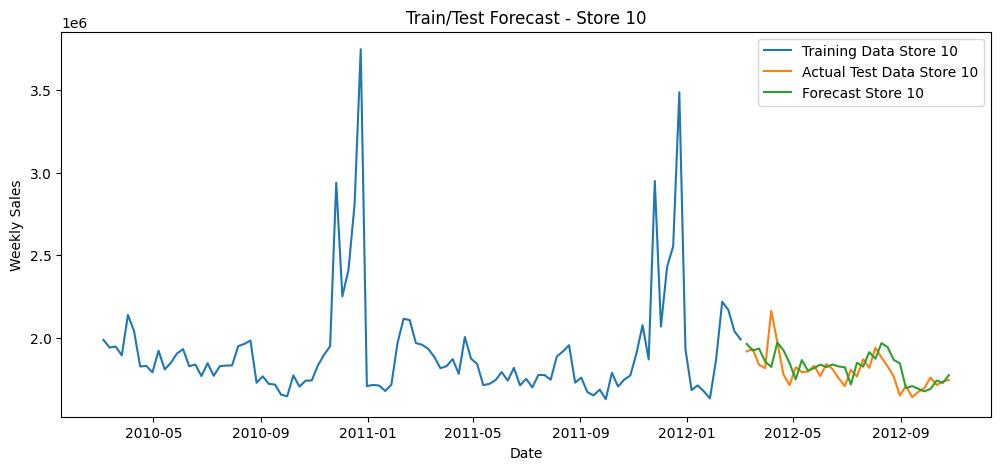

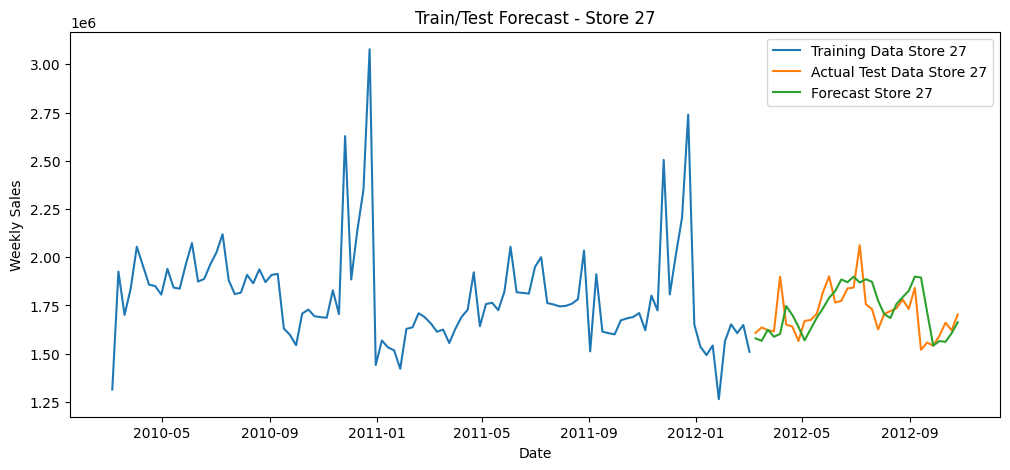

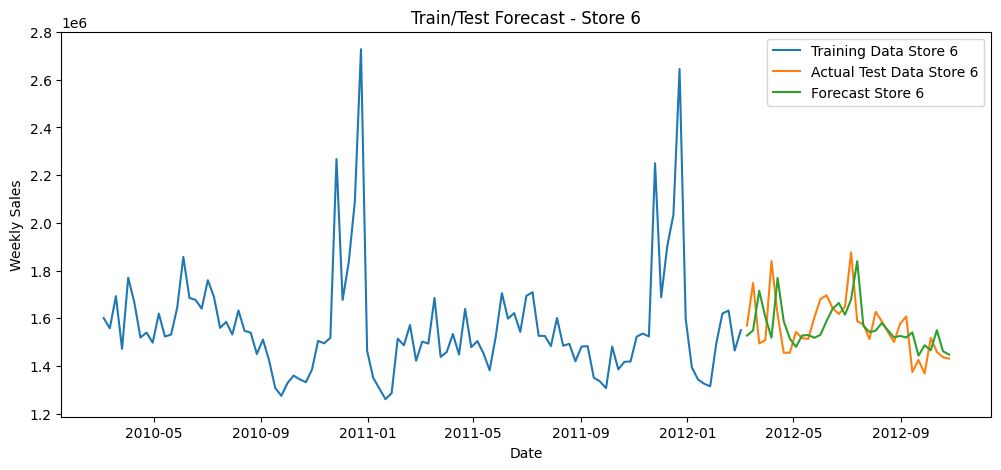

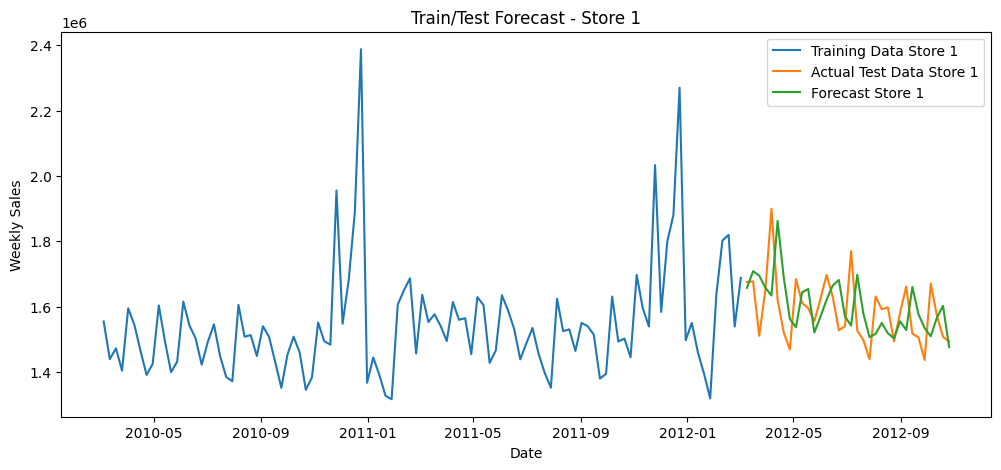

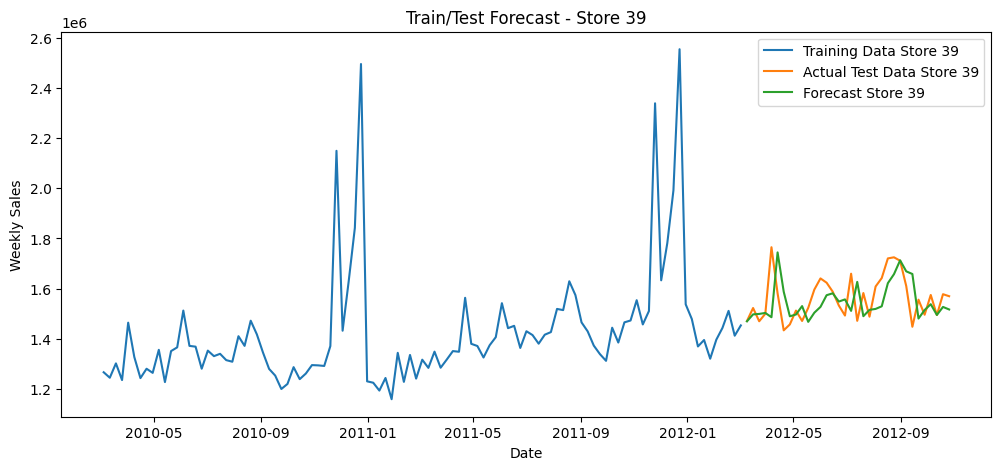

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv('/content/gdrive/MyDrive/Tina AI study/Walmart_Sales.csv', encoding='latin1')
# make it date, not test format; format is mixed, needs custom
df['Date'] = pd.to_datetime(
    df['Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)
df.head()
from numpy import log


store_sales = df.groupby('Store')['Weekly_Sales'].mean().reset_index()
store_sales = store_sales.sort_values(
    'Weekly_Sales',
    ascending=False
)

top_10_stores = store_sales.head(10)['Store'].tolist() # add top 10 stores to the list, they all were already listed in the table, i just take 10 top stores.
# print(f"Top 10 Stores: {top_10_stores}")

# Filter the original DataFrame to include only the top 10 stores
rf_df = df[df['Store'].isin(top_10_stores)].copy()

# Sort by Store and Date to ensure correct lag calculations within each store
rf_df = rf_df.sort_values(by=['Store', 'Date'])
#print(rf_df.head())

# print(best_store_df.head())

rf_df = rf_df[['Date', 'Store', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
                       'Fuel_Price', 'CPI', 'Unemployment']].copy()

# print(rf_df)

# print(rf_df.dtypes)
# Seasonal variable
rf_df['year'] = rf_df['Date'].dt.year
rf_df['month'] = rf_df['Date'].dt.month
rf_df['week'] = rf_df['Date'].dt.isocalendar().week.astype(int)

# weekly sales - Apply shift grouped by Store
rf_df['lag_1'] = rf_df.groupby('Store')['Weekly_Sales'].shift(1)
rf_df['lag_2'] = rf_df.groupby('Store')['Weekly_Sales'].shift(2)
rf_df['lag_3'] = rf_df.groupby('Store')['Weekly_Sales'].shift(3)
rf_df['lag_4'] = rf_df.groupby('Store')['Weekly_Sales'].shift(4)

##correlation on the features
corr_matrix = rf_df.corr()
#print("Corr Matrix:-\n",corr_matrix['Weekly_Sales'].sort_values(ascending=False))

rf_df = rf_df.dropna() #removing missing values, getting new rf_df

## Split by index doesn't work. It creates inconsistency in splitting the data, giving only 3 stores to work with which leads to the lack of stores to display in the plots.
## Not sure if im doing the right thing
## Instead, I will try splitting it by date
unique_dates = sorted(rf_df['Date'].unique())
split_date = unique_dates[int(len(unique_dates) * 0.75)]
print(split_date)


train_rf = rf_df[rf_df['Date']<=split_date]
test_rf = rf_df[rf_df['Date']>split_date]

# print("Stores in train:", sorted(train_rf['Store'].unique()))
# print("Stores in test:", sorted(test_rf['Store'].unique()))

features = ['Store', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_3', 'lag_4']

x_train = train_rf[features]
y_train = train_rf['Weekly_Sales']

x_test = test_rf[features]
y_test = test_rf['Weekly_Sales']

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train) #training
y_pred = rf_model.predict(x_test) #making a prediction after training.

# Estimate MAPE
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
#print("MAPE:", mape)


# plot RF
import matplotlib.pyplot as plt

print(test_rf['Store'].unique())

for store_to_plot in top_10_stores:


  train_rf_store = train_rf[train_rf['Store'] == store_to_plot].copy()
  test_rf_store = test_rf[test_rf['Store'] == store_to_plot].copy()

  x_test_store = test_rf_store[features]
  y_pred_store = rf_model.predict(x_test_store)

  plt.figure(figsize=(12, 5))

  plt.plot(
    train_rf_store['Date'],
    train_rf_store['Weekly_Sales'],
    label=f'Training Data Store {store_to_plot}'
  )

  plt.plot(
    test_rf_store['Date'],
    test_rf_store['Weekly_Sales'],
    label=f'Actual Test Data Store {store_to_plot}'
  )

  plt.plot(
    test_rf_store['Date'],
    y_pred_store,
    label=f'Forecast Store {store_to_plot}'
  )

  plt.xlabel('Date')
  plt.ylabel('Weekly Sales')
  plt.title(f'Train/Test Forecast - Store {store_to_plot}')
  plt.legend()
  plt.show()

In [ ]:
print("Full data date range:")
print(rf_df['Date'].min(), "to", rf_df['Date'].max())

print("\nTraining date range:")
print(train_rf['Date'].min(), "to", train_rf['Date'].max())

print("\nTesting date range:")
print(test_rf['Date'].min(), "to", test_rf['Date'].max())

Full data date range:
2010-03-05 00:00:00 to 2012-10-26 00:00:00

Training date range:
2010-03-05 00:00:00 to 2012-03-02 00:00:00

Testing date range:
2012-03-09 00:00:00 to 2012-10-26 00:00:00


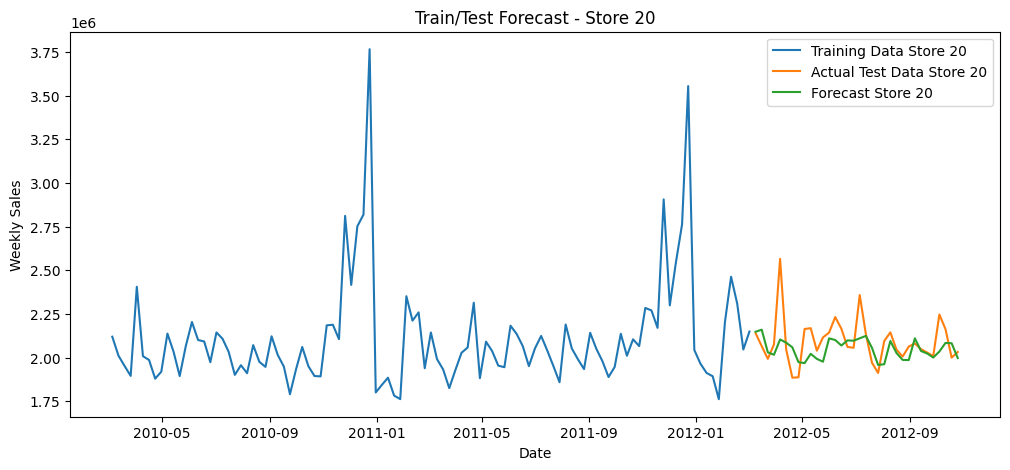

In [ ]:
store_to_plot = 20

train_rf_store = train_rf[train_rf['Store'] == store_to_plot].copy()
test_rf_store = test_rf[test_rf['Store'] == store_to_plot].copy()

x_test_store = test_rf_store[features]
y_pred_store = rf_model.predict(x_test_store)

plt.figure(figsize=(12, 5))

plt.plot(
    train_rf_store['Date'],
    train_rf_store['Weekly_Sales'],
    label=f'Training Data Store {store_to_plot}'
)

plt.plot(
    test_rf_store['Date'],
    test_rf_store['Weekly_Sales'],
    label=f'Actual Test Data Store {store_to_plot}'
)

plt.plot(
    test_rf_store['Date'],
    y_pred_store,
    label=f'Forecast Store {store_to_plot}'
)

plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title(f'Train/Test Forecast - Store {store_to_plot}')
plt.legend()
plt.show()

### Perform KNN outlier Imputation

Identifying and marking outliers in numerical columns of rf_df...

rf_df_cleaned head after marking outliers as NaN (showing some NaNs if outliers were present):
           Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
2721 2010-03-05    2119213.72           0.0        31.75       2.777   
2722 2010-03-12    2010974.84           0.0        43.82       2.818   
2723 2010-03-19    1951848.43           0.0        47.32       2.844   
2724 2010-03-26    1894742.95           0.0        50.49       2.854   
2725 2010-04-02    2405395.22           0.0        51.00       2.850   

             CPI  Unemployment    year  month  week       lag_1       lag_2  \
2721  204.494073           NaN  2010.0    3.0   9.0  1898193.95  2161549.76   
2722  204.525060           NaN  2010.0    3.0  10.0  2119213.72  1898193.95   
2723  204.378226           NaN  2010.0    3.0  11.0  2010974.84  2119213.72   
2724  204.201755           NaN  2010.0    3.0  12.0  1951848.43  2010974.84   
2725  204.

,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,year,month,week,lag_1,lag_2,lag_3,lag_4
2721,2010-03-05,2119213.72,0.0,31.75,2.777,204.494073,7.2628,2010.0,3.0,9.0,1898193.95,2161549.76,2109107.90,2401395.47
2722,2010-03-12,2010974.84,0.0,43.82,2.818,204.525060,7.2514,2010.0,3.0,10.0,2119213.72,1898193.95,2161549.76,2109107.90
2723,2010-03-19,1951848.43,0.0,47.32,2.844,204.378226,7.2158,2010.0,3.0,11.0,2010974.84,2119213.72,1898193.95,2161549.76
2724,2010-03-26,1894742.95,0.0,50.49,2.854,204.201755,7.1652,2010.0,3.0,12.0,1951848.43,2010974.84,2119213.72,1898193.95
2725,2010-04-02,2405395.22,0.0,51.00,2.850,204.025284,7.8560,2010.0,4.0,13.0,1894742.95,1951848.43,2010974.84,2119213.72


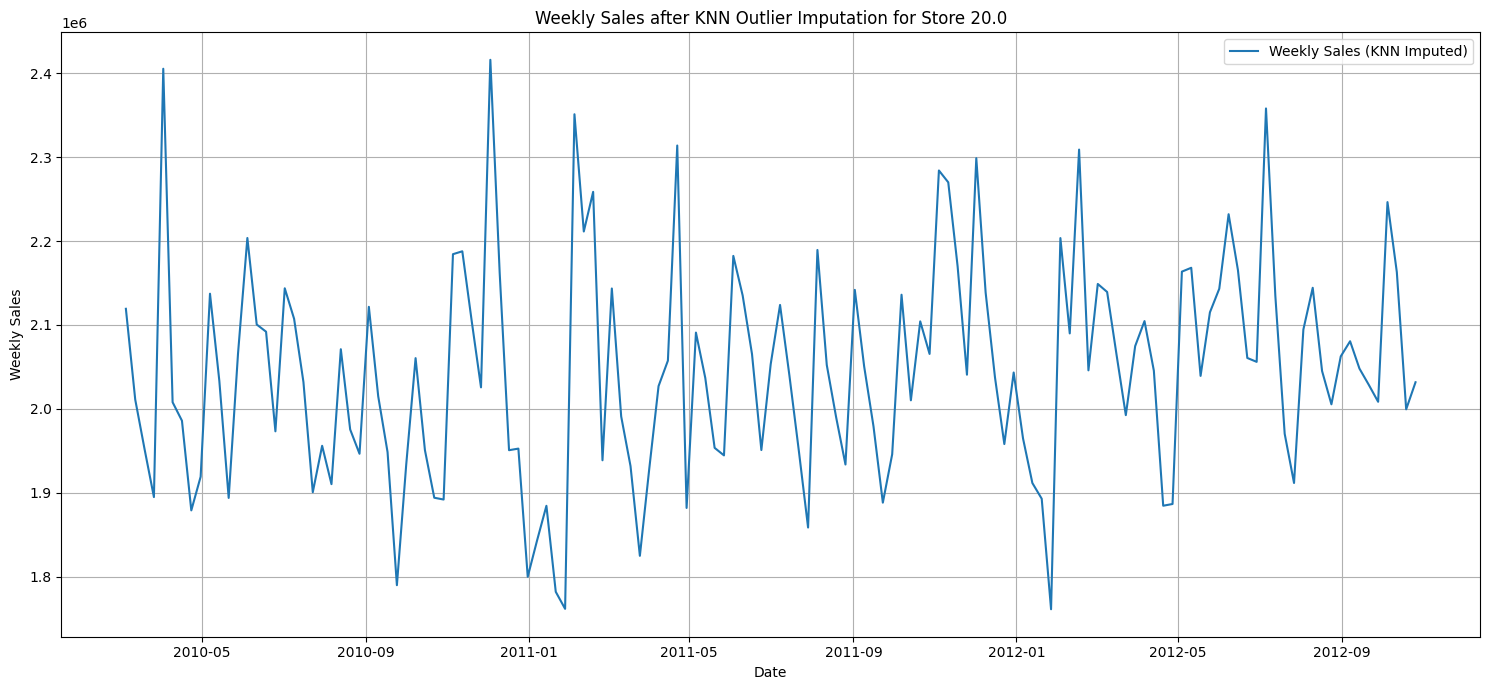

In [ ]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

# The dataframe to work with is rf_df from the random forest section
# Make a copy to avoid modifying the original rf_df prematurely
rf_df_cleaned = rf_df.copy()

# Identify numerical columns for imputation. Exclude 'Date' as it's not a numerical feature.
# We are including 'Weekly_Sales' as the user asked to impute outliers in "my dataset" broadly.
numerical_cols = rf_df_cleaned.select_dtypes(include=np.number).columns.tolist()

# Step 1: Identify and mark outliers as NaN (using IQR method as an example)
# This will be applied to all numerical columns, including 'Weekly_Sales'
print("Identifying and marking outliers in numerical columns of rf_df...")
for col in numerical_cols:
    Q1 = rf_df_cleaned[col].quantile(0.25)
    Q3 = rf_df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Mark outliers as NaN
    rf_df_cleaned[col] = np.where(
        (rf_df_cleaned[col] < lower_bound) | (rf_df_cleaned[col] > upper_bound),
        np.nan,
        rf_df_cleaned[col]
    )

print("\nrf_df_cleaned head after marking outliers as NaN (showing some NaNs if outliers were present):")
print(rf_df_cleaned.head())
print("\nNumber of NaN values after marking outliers (expected some if outliers were present):")
print(rf_df_cleaned[numerical_cols].isnull().sum())

# Step 2: Perform KNN Imputation on the columns with marked outliers
imputer = KNNImputer(n_neighbors=5) # You can adjust n_neighbors

# Fit and transform the data, only on the numerical columns with NaNs
rf_df_imputed_values = imputer.fit_transform(rf_df_cleaned[numerical_cols])

# Create a DataFrame from the imputed values
rf_df_imputed_numerical = pd.DataFrame(rf_df_imputed_values, columns=numerical_cols, index=rf_df_cleaned.index)

# Reintegrate these imputed numerical columns back into rf_df_cleaned
for col in numerical_cols:
    rf_df_cleaned[col] = rf_df_imputed_numerical[col]

print("\nrf_df_cleaned head after KNN imputation:")
print(rf_df_cleaned.head())
print("\nNumber of NaN values after KNN imputation (should be zero for numerical columns):")
print(rf_df_cleaned[numerical_cols].isnull().sum())

# Now, rf_df_cleaned contains the data with outliers imputed using KNN.
# You can now use rf_df_cleaned for further analysis, if desired.

import matplotlib.pyplot as plt

print("Head of the rf_df_cleaned DataFrame:")
display(rf_df_cleaned.head())

plt.figure(figsize=(15, 7))
plt.plot(rf_df_cleaned['Date'], rf_df_cleaned['Weekly_Sales'], label='Weekly Sales (KNN Imputed)')
plt.title('Weekly Sales after KNN Outlier Imputation for Store ' + str(best_store))
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### K-Fold Cross-Validation for Random Forest

To get a more robust evaluation of the Random Forest model, we can use k-fold cross-validation. This technique splits the dataset into 'k' folds, trains the model on 'k-1' folds, and validates it on the remaining fold. This process is repeated 'k' times, and the results are averaged.

We will use `KFold` to define the splitting strategy and `cross_val_score` to perform the cross-validation and calculate the mean absolute percentage error (MAPE) for each fold.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, ParameterGrid
import numpy as np
from sklearn.ensemble import RandomForestRegressor

## rdf cleaned is the knn outlier imputation strategy
rf_df = rf_df_cleaned.copy()
features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_4']
# Combine features and target for cross-validation
X = rf_df[features]
y = rf_df['Weekly_Sales']

# Define the K-fold splitter using TimeSeriesSplit
# n_splits determines the number of train/test splits.
# For example, with 5 splits, it will create 5 different train/test sets,
# where each test set comes after its corresponding training set.
kf = TimeSeriesSplit(n_splits=5)

# Define a custom scoring function for MAPE
def mape_scorer(estimator, X, y_true):
    y_pred = estimator.predict(X)
    # Ensure y_true does not contain zero to avoid division by zero
    y_true_safe = np.where(y_true == 0, 1e-10, y_true) # Replace zeros with a very small number
    return -np.mean(np.abs((y_true - y_pred) / y_true_safe)) * 100

# Define a grid of hyperparameters to search for RandomForestRegressor
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

all_params_rf = list(ParameterGrid(param_grid_rf))

mapes_rf = [] # To store the MAPE for each parameter combination

print(f'Total Random Forest models to evaluate: {len(all_params_rf)}')

# Iterate over each parameter combination
for i, params_rf in enumerate(all_params_rf):
    #print(f'Evaluating Random Forest model {i+1}/{len(all_params_rf)} with params: {params_rf}')

    # Create and fit a RandomForestRegressor model with the current parameters
    rf_model_tune = RandomForestRegressor(random_state=42, **params_rf)

    # Perform cross-validation and get MAPE scores
    # We'll use the negative MAPE from the scorer, so we need to negate it back for true MAPE
    cv_scores = cross_val_score(rf_model_tune, X, y, cv=kf, scoring=mape_scorer)
    print(cv_scores)
    # The scorer returns negative MAPE, so we take the mean of the negated scores
    mean_mape = -cv_scores.mean()

    mapes_rf.append(mean_mape)

# Find the best parameters based on the lowest MAPE
best_params_idx_rf = mapes_rf.index(min(mapes_rf))
best_params_rf = all_params_rf[best_params_idx_rf]

# print(f'\nBest Random Forest parameters found: {best_params_rf}')
# print(f'Lowest Mean MAPE achieved: {min(mapes_rf):.4f}')

# Retrain the final model using these best parameters on the full training data
final_rf_model = RandomForestRegressor(random_state=42, **best_params_rf)
final_rf_model.fit(X, y) # Fit on the full dataset (X, y)

# print('\nFinal Random Forest model trained with best parameters!')


Total Random Forest models to evaluate: 18
[-7.24115083 -6.02650277 -4.11312234 -4.20860964 -3.61372674]
[-7.23803675 -5.91397462 -3.99981661 -4.21531705 -3.41037609]
[-7.03961826 -5.91608765 -3.96784427 -4.22024901 -3.41028639]
[-7.19537917 -5.88255699 -4.19587275 -4.20646847 -3.60801379]
[-7.04314594 -5.87256    -4.0206886  -4.19761975 -3.3731846 ]
[-6.94947887 -5.91301072 -4.03432372 -4.20460051 -3.38613414]
[-7.24115083 -6.00889444 -4.07958927 -4.21420973 -3.5951806 ]
[-7.23803675 -5.91645926 -3.94235763 -4.13956989 -3.44167312]
[-7.03961826 -5.93461258 -3.97704645 -4.13905824 -3.41240432]
[-7.19537917 -5.88255699 -4.2020184  -4.17764889 -3.61267488]
[-7.04314594 -5.87256    -4.02321482 -4.17831742 -3.39539848]
[-6.94947887 -5.91403304 -4.02125634 -4.1899009  -3.38905833]
[-7.24115083 -6.02650277 -4.11312234 -4.20860964 -3.61372674]
[-7.23803675 -5.91397462 -3.99981661 -4.21531705 -3.41037609]
[-7.03961826 -5.91608765 -3.96784427 -4.22024901 -3.41028639]
[-7.19537917 -5.88255699 -4

RandomForestRegressor(max_depth=10, min_samples_split=5, n_estimators=200,
                      random_state=42)

MAPE: 3.157825524569237


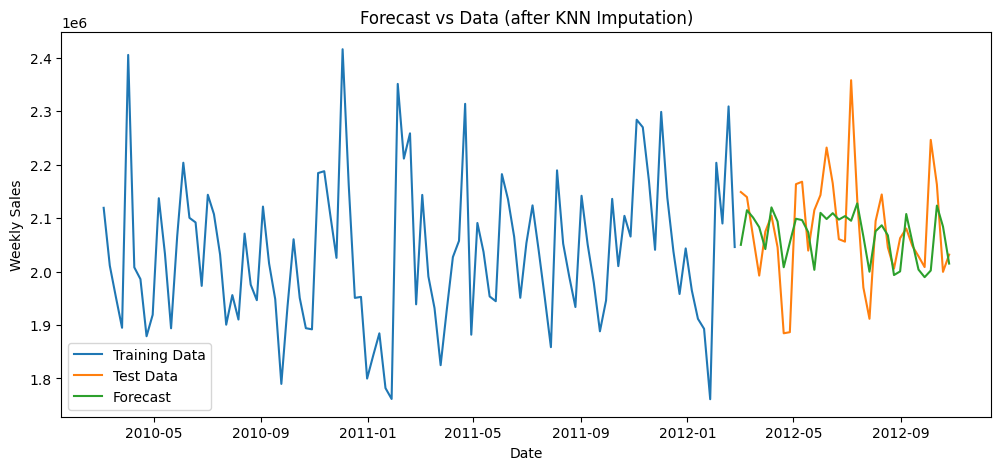

In [ ]:
### Using the best params from kfold to fit the randomforest,
from sklearn.ensemble import RandomForestRegressor

# Re-define train/test splits to ensure they use the cleaned rf_df
# rf_df is already updated to rf_df_cleaned in cell 1a9246af after imputation

# Ensure features list is consistent
features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_4']

split_ind = int(len(rf_df) * 0.75)

train_rf_cleaned = rf_df.iloc[:split_ind]
test_rf_cleaned = rf_df.iloc[split_ind:]

x_train = train_rf_cleaned[features]
y_train = train_rf_cleaned['Weekly_Sales']

x_test = test_rf_cleaned[features]
y_test = test_rf_cleaned['Weekly_Sales']

# Use the best_params_rf found during cross-validation
# The best_params_rf dictionary was determined in cell 1a9246af
# We will instantiate the RandomForestRegressor with these optimal parameters
rf_model = RandomForestRegressor(random_state=42, **best_params_rf)
rf_model.fit(x_train, y_train)

# Make predictions on the test set using the tuned model
y_pred = rf_model.predict(x_test)
# Estimate MAPE
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
print("MAPE:", mape)


# plot RF
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.plot(train_rf_cleaned['Date'], train_rf_cleaned['Weekly_Sales'], label='Training Data') # Use cleaned train data for plot
plt.plot(test_rf_cleaned['Date'], test_rf_cleaned['Weekly_Sales'], label='Test Data')     # Use cleaned test data for plot
plt.plot(test_rf_cleaned['Date'], y_pred, label='Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title('Forecast vs Data (after KNN Imputation)') # Update title to reflect imputation
plt.legend()
plt.show()

### Median Outlier Imputation

To compare the effect of different imputation strategies, let's re-prepare the `rf_df` DataFrame from the `best_store_df` (as done initially in the Random Forest section) to ensure we start with the original data before applying median imputation. This includes adding temporal features and lag features, and then dropping initial NaNs that result from lag creation.

In [ ]:
import pandas as pd
import numpy as np


# NOTE: For this to work correctly, the 'best_store_df' from cell YTqZEksPYCbe needs to be available
# from the global scope. Assuming it is.

rf_df_original = best_store_df[['Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
                       'Fuel_Price', 'CPI', 'Unemployment']].copy()

rf_df_original = rf_df_original.sort_values('Date')

# Seasonal variable
rf_df_original['year'] = rf_df_original['Date'].dt.year
rf_df_original['month'] = rf_df_original['Date'].dt.month
rf_df_original['week'] = rf_df_original['Date'].dt.isocalendar().week.astype(int)

# weekly sales
rf_df_original['lag_1'] = rf_df_original['Weekly_Sales'].shift(1)
rf_df_original['lag_2'] = rf_df_original['Weekly_Sales'].shift(2)
rf_df_original['lag_3'] = rf_df_original['Weekly_Sales'].shift(3)
rf_df_original['lag_4'] = rf_df_original['Weekly_Sales'].shift(4)

# Drop initial NaNs created by shift operations
rf_df_original = rf_df_original.dropna().copy()

print("Head of re-created rf_df_original:")
display(rf_df_original.head())
print("Number of NaNs in re-created rf_df_original:")
print(rf_df_original.isnull().sum())

Head of re-created rf_df_original:


,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,year,month,week,lag_1,lag_2,lag_3,lag_4
2721,2010-03-05,2119213.72,0,31.75,2.777,204.494073,8.187,2010,3,9,1898193.95,2161549.76,2109107.90,2401395.47
2722,2010-03-12,2010974.84,0,43.82,2.818,204.525060,8.187,2010,3,10,2119213.72,1898193.95,2161549.76,2109107.90
2723,2010-03-19,1951848.43,0,47.32,2.844,204.378226,8.187,2010,3,11,2010974.84,2119213.72,1898193.95,2161549.76
2724,2010-03-26,1894742.95,0,50.49,2.854,204.201755,8.187,2010,3,12,1951848.43,2010974.84,2119213.72,1898193.95
2725,2010-04-02,2405395.22,0,51.00,2.850,204.025284,7.856,2010,4,13,1894742.95,1951848.43,2010974.84,2119213.72


Number of NaNs in re-created rf_df_original:
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
year            0
month           0
week            0
lag_1           0
lag_2           0
lag_3           0
lag_4           0
dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer # used for mean, mode, median imputation
import matplotlib.pyplot as plt

# The dataframe to work with is rf_df_original
rf_df_median_imputed = rf_df_original.copy()

# Identify numerical columns for imputation. Exclude 'Date' as it's not numerical.
numerical_cols = rf_df_median_imputed.select_dtypes(include=np.number).columns.tolist()

# Step 1: Identify and mark outliers as NaN (using IQR method)
print("Identifying and marking outliers in numerical columns of rf_df_median_imputed...")
for col in numerical_cols:
    Q1 = rf_df_median_imputed[col].quantile(0.25)
    Q3 = rf_df_median_imputed[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Mark outliers as NaN
    rf_df_median_imputed[col] = np.where(
        (rf_df_median_imputed[col] < lower_bound) | (rf_df_median_imputed[col] > upper_bound),
        np.nan,
        rf_df_median_imputed[col]
    )

print("\nrf_df_median_imputed head after marking outliers as NaN:")
print(rf_df_median_imputed.head())
print("\nNumber of NaN values after marking outliers:")
print(rf_df_median_imputed[numerical_cols].isnull().sum())

# Step 2: Perform Median Imputation on the columns with marked outliers
imputer_median = SimpleImputer(strategy='median')

# Fit and transform the data, only on the numerical columns with NaNs
rf_df_imputed_values_median = imputer_median.fit_transform(rf_df_median_imputed[numerical_cols])

# Create a DataFrame from the imputed values
rf_df_imputed_numerical_median = pd.DataFrame(rf_df_imputed_values_median, columns=numerical_cols, index=rf_df_median_imputed.index)

# Reintegrate these imputed numerical columns back into rf_df_median_imputed
for col in numerical_cols:
    rf_df_median_imputed[col] = rf_df_imputed_numerical_median[col]

print("\nrf_df_median_imputed head after Median imputation:")
print(rf_df_median_imputed.head())
print("\nNumber of NaN values after Median imputation (should be zero for numerical columns):")
print(rf_df_median_imputed[numerical_cols].isnull().sum())

# Now, rf_df_median_imputed contains the data with outliers imputed using median.

print("Head of the rf_df_median_imputed DataFrame:")
display(rf_df_median_imputed.head())

plt.figure(figsize=(15, 7))
plt.plot(rf_df_median_imputed['Date'], rf_df_median_imputed['Weekly_Sales'], label='Weekly Sales (Median Imputed)')
plt.title('Weekly Sales after Median Outlier Imputation for Store ' + str(best_store))
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

NameError: name 'rf_df_original' is not defined

Now that we have the `rf_df_median_imputed` DataFrame, we can proceed to train and evaluate a Random Forest model using this data, similar to how we did with the KNN imputed data.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, ParameterGrid

# Use the rf_df_median_imputed for further modeling
rf_df_current = rf_df_median_imputed.copy()

features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_4']

X_median = rf_df_current[features]
y_median = rf_df_current['Weekly_Sales']

# Define the K-fold splitter using TimeSeriesSplit
kf_median = TimeSeriesSplit(n_splits=5)

# Define a custom scoring function for MAPE
def mape_scorer(estimator, X, y_true):
    y_pred = estimator.predict(X)
    y_true_safe = np.where(y_true == 0, 1e-10, y_true)
    return -np.mean(np.abs((y_true - y_pred) / y_true_safe)) * 100

# Use the same hyperparameter grid as before for consistency
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

all_params_rf_median = list(ParameterGrid(param_grid_rf))

mapes_rf_median = []

print(f'Total Random Forest models to evaluate with Median Imputation: {len(all_params_rf_median)}')

for i, params_rf in enumerate(all_params_rf_median):
    print(f'Evaluating Random Forest model {i+1}/{len(all_params_rf_median)} with params: {params_rf}')

    rf_model_tune = RandomForestRegressor(random_state=42, **params_rf)
    cv_scores = cross_val_score(rf_model_tune, X_median, y_median, cv=kf_median, scoring=mape_scorer)
    mean_mape = -cv_scores.mean()
    mapes_rf_median.append(mean_mape)

best_params_idx_rf_median = mapes_rf_median.index(min(mapes_rf_median))
best_params_rf_median = all_params_rf_median[best_params_idx_rf_median]

print(f'\nBest Random Forest parameters found with Median Imputation: {best_params_rf_median}')
print(f'Lowest Mean MAPE achieved with Median Imputation: {min(mapes_rf_median):.4f}')

# Retrain the final model using these best parameters on the full dataset
final_rf_model_median = RandomForestRegressor(random_state=42, **best_params_rf_median)
final_rf_model_median.fit(X_median, y_median)

print('\nFinal Random Forest model trained with best parameters (Median Imputation)!')

Total Random Forest models to evaluate with Median Imputation: 18
Evaluating Random Forest model 1/18 with params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Evaluating Random Forest model 2/18 with params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Evaluating Random Forest model 3/18 with params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Evaluating Random Forest model 4/18 with params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Evaluating Random Forest model 5/18 with params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
Evaluating Random Forest model 6/18 with params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Evaluating Random Forest model 7/18 with params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 50}
Evaluating Random Forest model 8/18 with params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Evaluating Random Forest mode

MAPE with Median Imputation: 1.5043157401829366


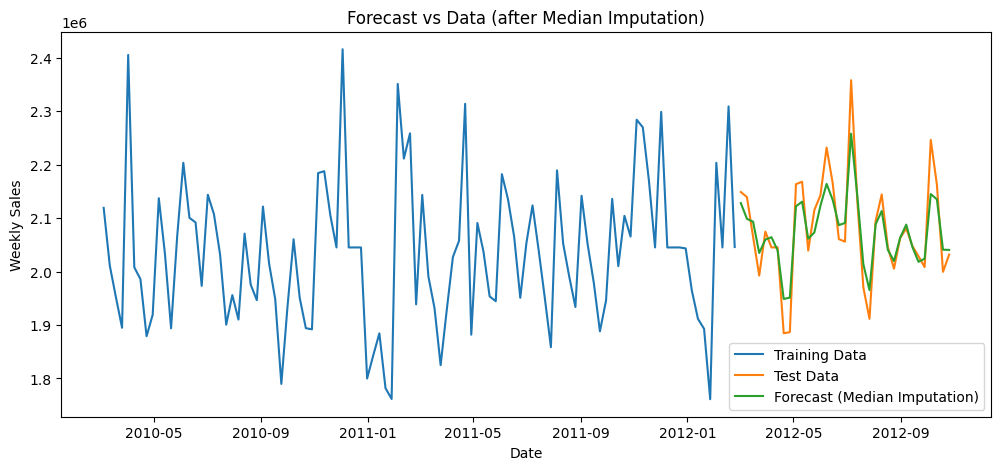

In [ ]:
# Re-define train/test splits for evaluation with median imputed data
split_ind_median = int(len(rf_df_current) * 0.75)

train_rf_median_imputed = rf_df_current.iloc[:split_ind_median]
test_rf_median_imputed = rf_df_current.iloc[split_ind_median:]

x_train_median = train_rf_median_imputed[features]
y_train_median = train_rf_median_imputed['Weekly_Sales']

x_test_median = test_rf_median_imputed[features]
y_test_median = test_rf_median_imputed['Weekly_Sales']

# Predict using the final model trained with best parameters from median imputation
y_pred_median = final_rf_model_median.predict(x_test_median)

# Estimate MAPE
mape_median = np.mean(np.abs((y_test_median - y_pred_median) / y_test_median)) * 100
print("MAPE with Median Imputation:", mape_median)

# plot RF with Median Imputation
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.plot(train_rf_median_imputed['Date'], train_rf_median_imputed['Weekly_Sales'], label='Training Data')
plt.plot(test_rf_median_imputed['Date'], test_rf_median_imputed['Weekly_Sales'], label='Test Data')
plt.plot(test_rf_median_imputed['Date'], y_pred_median, label='Forecast (Median Imputation)')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title('Forecast vs Data (after Median Imputation)')
plt.legend()
plt.show()

##Prophet

Mounted at /content/gdrive
        Date  Weekly_Sales
0 2010-02-05   49750740.50
1 2010-02-12   48336677.63
2 2010-02-19   48276993.78
3 2010-02-26   43968571.13
4 2010-03-05   46871470.30
Basic statictical analisys
                      Date  Weekly_Sales
count                  143  1.430000e+02
mean   2011-06-17 00:00:00  4.711342e+07
min    2010-02-05 00:00:00  3.959985e+07
25%    2010-10-11 12:00:00  4.488059e+07
50%    2011-06-17 00:00:00  4.624390e+07
75%    2012-02-20 12:00:00  4.779202e+07
max    2012-10-26 00:00:00  8.093142e+07
std                    NaN  5.444206e+06


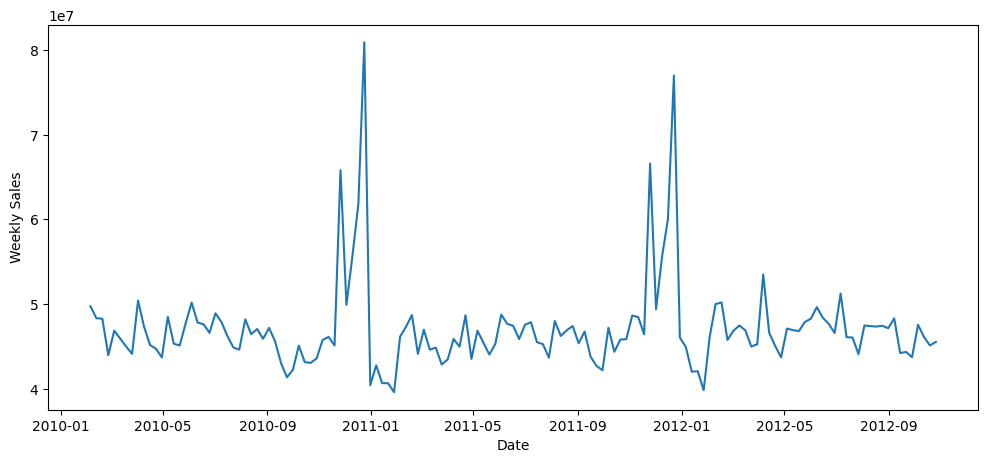

          ds            y
0 2010-02-05  49750740.50
1 2010-02-12  48336677.63
2 2010-02-19  48276993.78
3 2010-02-26  43968571.13
4 2010-03-05  46871470.30
train
            ds            y
0   2010-02-05  49750740.50
1   2010-02-12  48336677.63
2   2010-02-19  48276993.78
3   2010-02-26  43968571.13
4   2010-03-05  46871470.30
..         ...          ...
102 2012-01-20  42080996.56
103 2012-01-27  39834974.67
104 2012-02-03  46085608.09
105 2012-02-10  50009407.92
106 2012-02-17  50197056.96

[107 rows x 2 columns]
test
            ds            y
107 2012-02-24  45771506.57
108 2012-03-02  46861034.97
109 2012-03-09  47480454.11
110 2012-03-16  46901504.94
111 2012-03-23  44993794.45
112 2012-03-30  45272862.02
113 2012-04-06  53502315.87
114 2012-04-13  46629261.41
115 2012-04-20  45072529.78
116 2012-04-27  43716798.89
117 2012-05-04  47124197.93
118 2012-05-11  46925878.99
119 2012-05-18  46823939.22
120 2012-05-25  47892463.31
121 2012-06-01  48281649.72
122 2012-06-08  49651171.

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

# !ls "/content/gdrive/MyDrive/Tina AI study"


import pandas as pd
from prophet import Prophet
import io
# Replace 'filename.csv' with your actual file name
df = pd.read_csv('/content/gdrive/MyDrive/Tina AI study/Walmart_Sales.csv', encoding='latin1')
# print(df)
# print(df.columns)
# print(df)
df['Date'] = pd.to_datetime(df['Date'],
                            format = 'mixed',
                            dayfirst = True,
                            errors = 'coerce')
#print(df.sort_values('Date')) #sorted by date from earliest to latest
#print(df.isnull().sum()) #zero outliers
#print(df.info())
#print(df.duplicated().sum()) # no duplicates

sales_by_date = df.groupby('Date')['Weekly_Sales'].sum().reset_index()
sales_by_date = sales_by_date.sort_values('Date')
print(sales_by_date.head())

# EDA
print("Basic statictical analisys")
print(sales_by_date.describe())

# plotting
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(sales_by_date['Date'], sales_by_date['Weekly_Sales'])
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.show()

#datapreparation
prophet_df = sales_by_date.rename(columns={
    'Date' : 'ds',
    'Weekly_Sales' : 'y'
})
print(prophet_df.head())
arima = sales_by_date.set_index('Date')['Weekly_Sales']

#split 80% 20%
split_ind = int(len(sales_by_date) * 0.75)
train = sales_by_date.iloc[:split_ind]
##change the column names
train.columns = ['ds', 'y']
print('train')
print(train)
test = sales_by_date.iloc[split_ind:]
test.columns = ['ds', 'y']
print('test')
print(test)

model_pr = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)
model_pr.fit(train)

future = test[['ds']]
forecast = model_pr.predict(future)
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

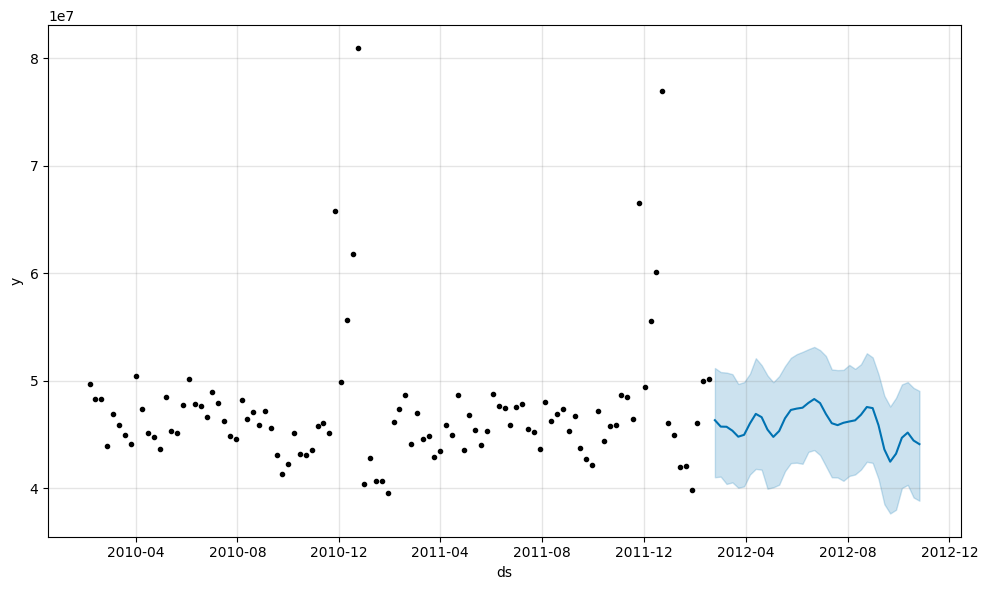

In [ ]:
fig1 = model_pr.plot(forecast)

In [ ]:
from prophet.plot import plot_plotly, plot_components_plotly

plot_plotly(model_pr, forecast)

In [ ]:
##evaluation metrics
##performance of the model
#merge actual and predicted data

df_perf = pd.merge(test, forecast[['ds', 'yhat']], on='ds', how='left')
df_perf.columns = ['ds', 'y_actual', 'y_pred']
df_perf

##calculate MAPE using sklearn library
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(df_perf['y_actual'], df_perf['y_pred'])
print(mape)
#

0.027829311996567598


In [ ]:
##With cross validation
from prophet.diagnostics import cross_validation
df_cv = cross_validation(model_pr, initial='520 days', period='90 days', horizon = '180 days')
df_cv.head()

INFO:prophet:Making 1 forecasts with cutoffs between 2011-08-21 00:00:00 and 2011-08-21 00:00:00


  0%|          | 0/1 [00:00<?, ?it/s]

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2011-08-26,4.710584e+07,4.277724e+07,5.154677e+07,47416948.45,2011-08-21
1,2011-09-02,4.635070e+07,4.180575e+07,5.065468e+07,45376623.27,2011-08-21
2,2011-09-09,4.425738e+07,3.936235e+07,4.842588e+07,46763227.53,2011-08-21
3,2011-09-16,4.206445e+07,3.755304e+07,4.658407e+07,43793960.08,2011-08-21
4,2011-09-23,4.133309e+07,3.694542e+07,4.585462e+07,42718096.73,2011-08-21


In [ ]:
from prophet.diagnostics import performance_metrics
df_p = performance_metrics(df_cv)
df_p.head()

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,12 days,5.228077e+11,7.230544e+05,6.425945e+05,0.014014,0.014014,0.013911,1.0
1,19 days,3.614059e+12,1.901068e+06,1.739964e+06,0.037526,0.037526,0.038150,1.0
2,26 days,4.635255e+12,2.152964e+06,2.117682e+06,0.046539,0.046539,0.047674,1.0
3,33 days,2.454728e+12,1.566757e+06,1.557259e+06,0.035957,0.035957,0.036622,1.0
4,40 days,9.600853e+11,9.798394e+05,7.144671e+05,0.016732,0.016732,0.016998,1.0


/usr/local/lib/python3.12/dist-packages/prophet/plot.py:547: FutureWarning:

Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.

/usr/local/lib/python3.12/dist-packages/prophet/plot.py:548: FutureWarning:

Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.



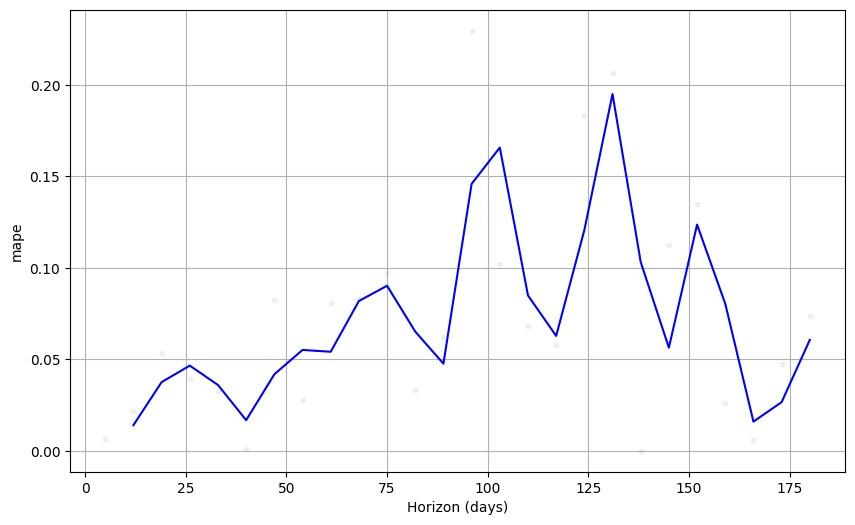

In [ ]:
from prophet.plot import plot_cross_validation_metric
fig = plot_cross_validation_metric(df_cv, metric='mape')


### Hyperparameter Tuning with Cross-Validation

We will define a range of `changepoint_prior_scale` values and evaluate the model performance for each using cross-validation. The `changepoint_prior_scale` determines the flexibility of the trend. A higher value means the trend can change more, while a lower value makes the trend more rigid.

In [ ]:
from sklearn.model_selection import ParameterGrid

# Define a grid of hyperparameters to search
param_grid = {
    'changepoint_prior_scale': [0.001, 0.01, 0.1, 0.5],
    'seasonality_prior_scale': [0.01, 0.1, 1.0, 10.0]
}

all_params = list(ParameterGrid(param_grid))

rmses = []  # To store the RMSE for each parameter combination
mapes = [] # To store the MAPE for each parameter combination

print(f'Total models to evaluate: {len(all_params)}')

# Iterate over each parameter combination
for i, params in enumerate(all_params):
    print(f'Evaluating model {i+1}/{len(all_params)} with params: {params}')

    # Create and fit a Prophet model with the current parameters
    model_tune = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        **params # Unpack the dictionary of parameters
    )
    model_tune.fit(train)

    # Perform cross-validation
    df_cv_tune = cross_validation(model_tune, initial='520 days', period='90 days', horizon = '180 days')

    # Calculate performance metrics
    df_p_tune = performance_metrics(df_cv_tune, metrics=['rmse', 'mape'])

    # Get the mean RMSE and MAPE over the horizon (or a specific horizon if desired)
    mean_rmse = df_p_tune['rmse'].mean()
    mean_mape = df_p_tune['mape'].mean()

    rmses.append(mean_rmse)
    mapes.append(mean_mape)

# Find the best parameters based on RMSE or MAPE
# For example, let's find the combination with the lowest MAPE
best_params_idx = mapes.index(min(mapes))
best_params = all_params[best_params_idx]

print(f'\nBest parameters found: {best_params}')
print(f'Lowest MAPE achieved: {min(mapes):.4f}')
print(f'Corresponding RMSE: {rmses[best_params_idx]:.2f}')

# Now, you would retrain your final model using these best parameters
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    **best_params
)
final_model.fit(prophet_df) # Fit on the full dataset or desired training data

print('\nFinal model trained with best parameters!')


Total models to evaluate: 16
Evaluating model 1/16 with params: {'changepoint_prior_scale': 0.001, 'seasonality_prior_scale': 0.01}


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
INFO:prophet:Making 1 forecasts with cutoffs between 2011-08-21 00:00:00 and 2011-08-21 00:00:00


  0%|          | 0/1 [00:00<?, ?it/s]

ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted


Evaluating model 2/16 with params: {'changepoint_prior_scale': 0.001, 'seasonality_prior_scale': 0.1}


...

  0%|          | 0/1 [00:00<?, ?it/s]

INFO:prophet:Making 1 forecasts with cutoffs between 2011-08-21 00:00:00 and 2011-08-21 00:00:00


Evaluating model 16/16 with params: {'changepoint_prior_scale': 0.5, 'seasonality_prior_scale': 10.0}


  0%|          | 0/1 [00:00<?, ?it/s]


Best parameters found: {'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 0.01}
Lowest MAPE achieved: 0.0587
Corresponding RMSE: 3915105.40

Final model trained with best parameters!


After running the code above, you would have identified the `best_params` for your model. You can then use this `final_model` with the optimized parameters to make new forecasts or evaluate its performance on a test set (if you still have one separate from the data used for cross-validation).

## Classification

Mounted at /content/gdrive
class
0    60.595523
1    39.404477
Name: proportion, dtype: float64


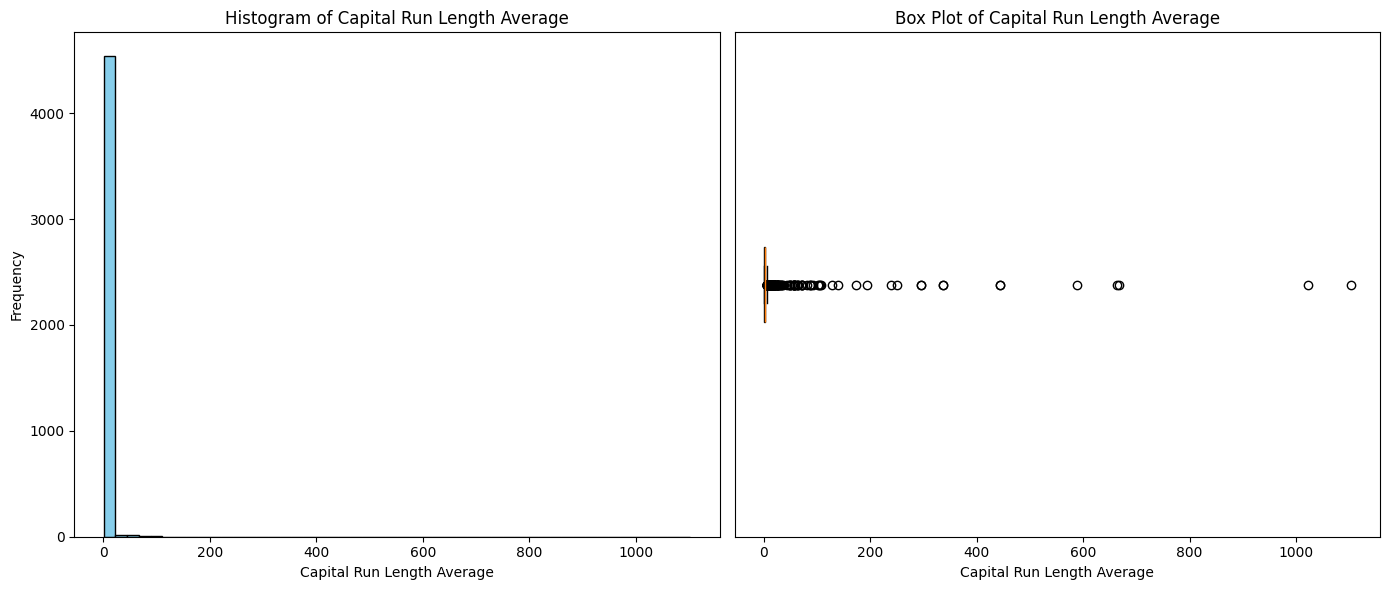

[1 1 0 1 0 0 0 1 0 0]
Accuracy: 0.92


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

import pandas as pd

df = pd.read_csv('/content/gdrive/MyDrive/Tina AI study/spambase_csv.csv', encoding='latin1')
df.columns = df.columns.str.strip() # remove spacing
print(df['class'].value_counts(normalize=True) * 100)

#print(df.head())

#print(df.isnull().sum()) # no missing values
#print(df.info())
# print(df['class'].value_counts()) # distribution of spam and not spam
#print(df.describe())

### The distribution is imbalanced

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
plt.hist(df['capital_run_length_average'], bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Capital Run Length Average')
plt.xlabel('Capital Run Length Average')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
plt.boxplot(df['capital_run_length_average'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('Box Plot of Capital Run Length Average')
plt.xlabel('Capital Run Length Average')
plt.yticks([]) # Hide y-axis ticks for better visualization

plt.tight_layout()
plt.show()

# splitting data into training and testing

X = df.drop('class', axis=1) # features
y = df['class'] # target is the answer column

# splitting data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y #keeps the same class ratio, no impalancing
)


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)
lr_model.fit(X_train_scaled, y_train)

# prediction
y_pred = lr_model.predict(X_test_scaled)

print(y_pred[:10])

# accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")








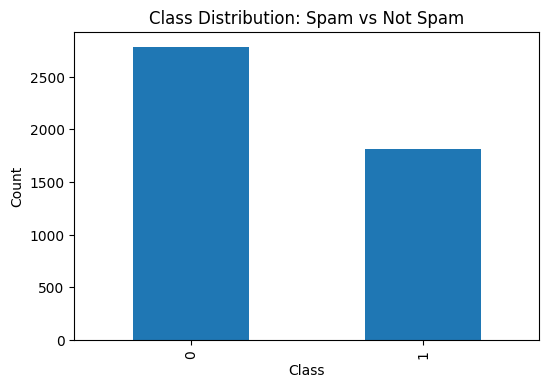

In [ ]:
plt.figure(figsize=(6, 4))
df['class'].value_counts().plot(kind='bar')
plt.title('Class Distribution: Spam vs Not Spam')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

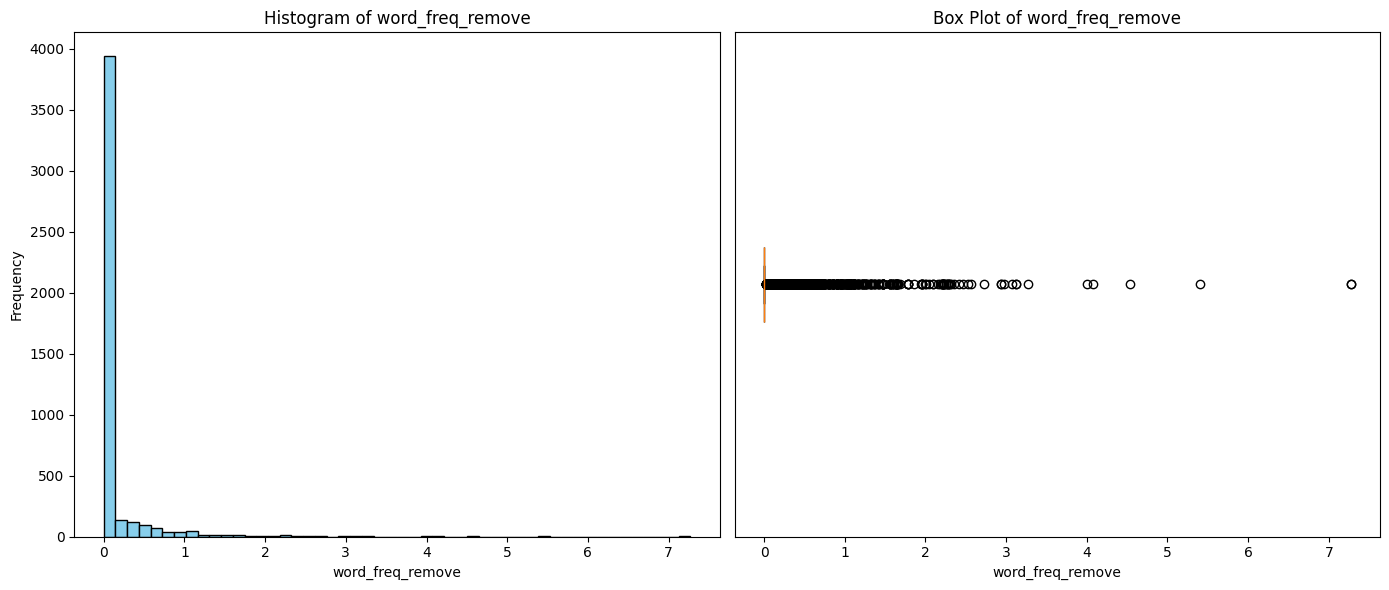

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
plt.hist(df['word_freq_remove'], bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of word_freq_remove')
plt.xlabel('word_freq_remove')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
plt.boxplot(df['word_freq_remove'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('Box Plot of word_freq_remove')
plt.xlabel('word_freq_remove')
plt.yticks([]) # Hide y-axis ticks for better visualization

plt.tight_layout()
plt.show()

In [ ]:
df.columns

Index(['word_freq_make', 'word_freq_address', 'word_freq_all', 'word_freq_3d',
       'word_freq_our', 'word_freq_over', 'word_freq_remove',
       'word_freq_internet', 'word_freq_order', 'word_freq_mail',
       'word_freq_receive', 'word_freq_will', 'word_freq_people',
       'word_freq_report', 'word_freq_addresses', 'word_freq_free',
       'word_freq_business', 'word_freq_email', 'word_freq_you',
       'word_freq_credit', 'word_freq_your', 'word_freq_font', 'word_freq_000',
       'word_freq_money', 'word_freq_hp', 'word_freq_hpl', 'word_freq_george',
       'word_freq_650', 'word_freq_lab', 'word_freq_labs', 'word_freq_telnet',
       'word_freq_857', 'word_freq_data', 'word_freq_415', 'word_freq_85',
       'word_freq_technology', 'word_freq_1999', 'word_freq_parts',
       'word_freq_pm', 'word_freq_direct', 'word_freq_cs', 'word_freq_meeting',
       'word_freq_original', 'word_freq_project', 'word_freq_re',
       'word_freq_edu', 'word_freq_table', 'word_freq_conference',


[1 1 0 1 0 0 0 1 0 1]
Random Forest Accuracy: 0.94
                       Feature  Importance
51               char_freq_%21    0.116716
52               char_freq_%24    0.091809
6             word_freq_remove    0.065571
54  capital_run_length_average    0.062698
55  capital_run_length_longest    0.060152
15              word_freq_free    0.059959
56    capital_run_length_total    0.058943
20              word_freq_your    0.056148
24                word_freq_hp    0.047402
18               word_freq_you    0.034132
26            word_freq_george    0.029599
4                word_freq_our    0.027329
23             word_freq_money    0.024156
25               word_freq_hpl    0.021828
22               word_freq_000    0.021083
45               word_freq_edu    0.020237
7           word_freq_internet    0.013454
49               char_freq_%28    0.012732
11              word_freq_will    0.012633
36              word_freq_1999    0.012278


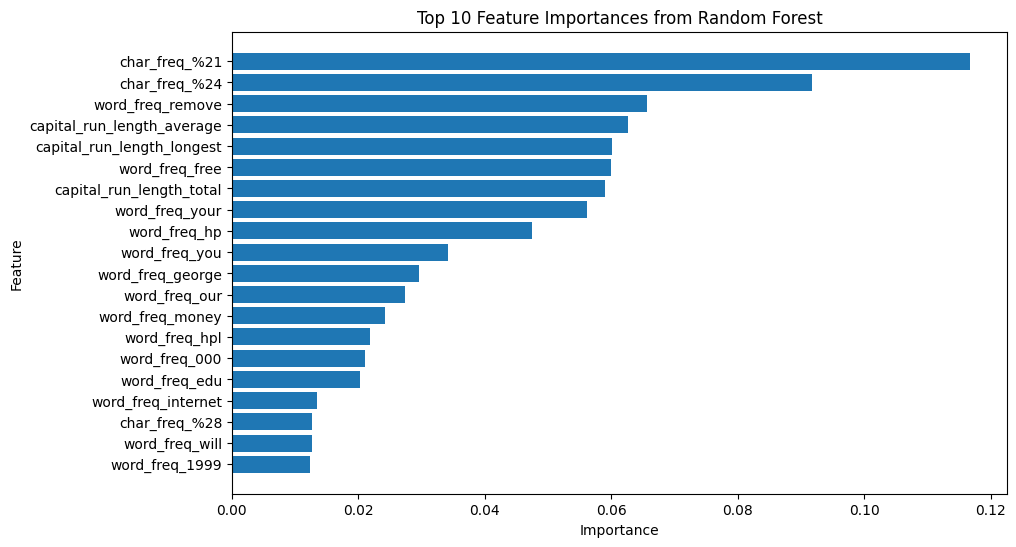

In [ ]:
###Random Forest classification

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train) # train the model with training data

y_pred_rf = rf_model.predict(X_test)
print(y_pred_rf[:10])

accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy_rf:.2f}")

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# this tells us what features were useful in training
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(20)) # print top 10

#plotting
import matplotlib.pyplot as plt

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances from Random Forest')
plt.gca().invert_yaxis()
plt.show()

Logistic Regression Metrics:
Accuracy: 0.93
Precision: 0.92
Recall: 0.90
F1 Score: 0.91

Random Forest Metrics:
Accuracy: 0.94
Precision: 0.95
Recall: 0.91
F1 Score: 0.93


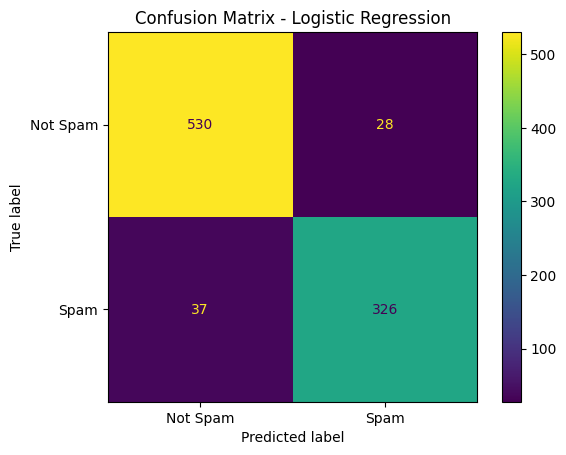


Logistic Regression Confusion Matrix:
[[530  28]
 [ 37 326]]


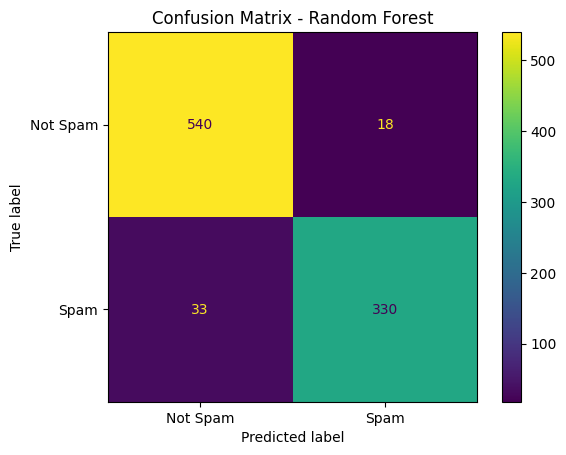


Random Forest Confusion Matrix:
[[540  18]
 [ 33 330]]

Model Comparison:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.929425   0.920904  0.898072  0.909344
1        Random Forest  0.944625   0.948276  0.909091  0.928270


In [ ]:
### Model evaluation and comparison
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# logistic regression
l_acc = accuracy_score(y_test, y_pred)
l_prec = precision_score(y_test, y_pred)
l_rec = recall_score(y_test, y_pred)
l_f1 = f1_score(y_test, y_pred)

print("Logistic Regression Metrics:")
print(f"Accuracy: {l_acc:.2f}")
print(f"Precision: {l_prec:.2f}")
print(f"Recall: {l_rec:.2f}")
print(f"F1 Score: {l_f1:.2f}")

# random forest classification
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf)
rf_rec = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("\nRandom Forest Metrics:")
print(f"Accuracy: {rf_acc:.2f}")
print(f"Precision: {rf_prec:.2f}")
print(f"Recall: {rf_rec:.2f}")
print(f"F1 Score: {rf_f1:.2f}")

#Confusion matrix
cm_lr = confusion_matrix(y_test, y_pred)
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['Not Spam', 'Spam']
)
disp_lr.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


print("\nLogistic Regression Confusion Matrix:")
print(cm_lr)


cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Not Spam', 'Spam']
)
disp_rf.plot()
plt.title('Confusion Matrix - Random Forest')
plt.show()


print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

# comparison
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [l_acc, rf_acc],
    'Precision': [l_prec, rf_prec],
    'Recall': [l_rec, rf_rec],
    'F1 Score': [l_f1, rf_f1]
})

print("\nModel Comparison:")
print(comparison)

In [ ]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear')

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print(y_pred_svm[:10])

accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"SVM Accuracy: {accuracy_svm:.2f}")

[1 1 0 1 0 0 0 1 0 0]
SVM Accuracy: 0.93


Mounted at /content/gdrive
TARGET
0    98.320999
1     1.679001
Name: proportion, dtype: float64
Before SMOTE:
TARGET
0    19769
1      338
Name: count, dtype: int64
After SMOTE:
TARGET
0    19769
1     4942
Name: count, dtype: int64
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4943
           1       0.85      0.69      0.76        84

    accuracy                           0.99      5027
   macro avg       0.92      0.84      0.88      5027
weighted avg       0.99      0.99      0.99      5027



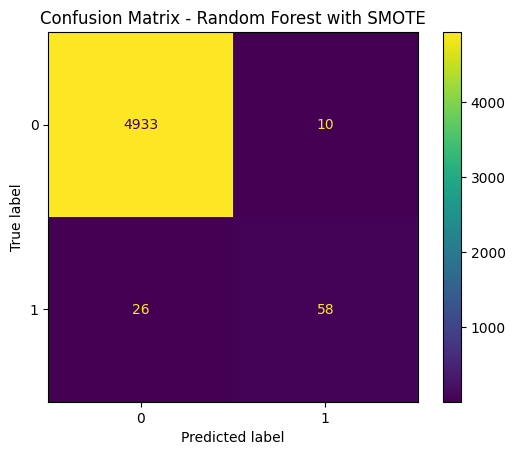

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

import pandas as pd

df = pd.read_csv('/content/gdrive/MyDrive/Tina AI study/credit_dataset.csv', encoding='latin1')
df.columns = df.columns.str.strip() # remove spacing
print(df['TARGET'].value_counts(normalize=True) * 100)

#print(df.head())
X = df.drop('TARGET', axis=1) # features
y = df['TARGET'] # target is the answer column

# splitting data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y #keeps the same class ratio, no impalancing
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy=0.25,
    random_state=42
)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("After SMOTE:")
print(y_train_smote.value_counts())

# fit and predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train_smote, y_train_smote)

y_pred_rf = rf_model.predict(X_test_processed)

print(classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Random Forest with SMOTE")
plt.show()


        Before SMOTE  After SMOTE
TARGET                           
0              19769        19769
1                338         4942


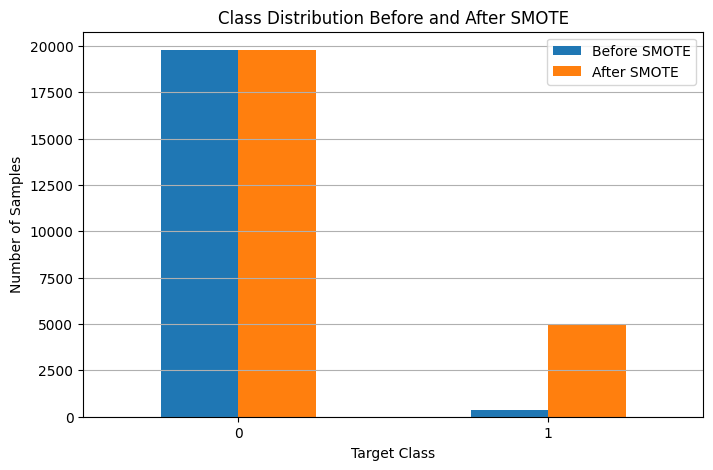

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

before_counts = y_train.value_counts().sort_index()
after_counts = y_train_smote.value_counts().sort_index()

imbalance_df = pd.DataFrame({
    'Before SMOTE': before_counts,
    'After SMOTE': after_counts
}).fillna(0)

print(imbalance_df)

imbalance_df.plot(kind='bar', figsize=(8, 5))

plt.title('Class Distribution Before and After SMOTE')
plt.xlabel('Target Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()